# IT Vacancy Seniority Classification
Astana IT University | Machine Learning Algorithms | Zholdubayev Diyar and Galymzhan Turemuratov

Synthetic snapshot, heuristic labels, exact saved 1000/250 split. Scenario B is primary. Macro F1 gives all three classes equal weight. Models and hyperparameters are selected by training-only stratified 5-fold CV. Test data are used for final reporting. This notebook reruns the complete modular experiment; original Midterm files are immutable.

In [2]:
from pathlib import Path
import sys
ROOT = Path.cwd()
if not (ROOT / 'src').exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
from src.project import load_data, load_split, original_hashes
from src.run_experiments import run
from threadpoolctl import threadpool_limits
import pandas as pd
from IPython.display import display, Image
df = load_data()
train, test = load_split(df)
print('Rows:', len(df), 'Train:', len(train), 'Test:', len(test))
print(df.grade.value_counts().to_string())

Rows: 1250 Train: 1000 Test: 250
grade
Middle    470
Junior    396
Senior    384


In [3]:
import importlib
import src.run_experiments as experiments
importlib.reload(experiments)
with threadpool_limits(limits=1):
    comparison = experiments.run()
display(comparison.round(4))

Validated dataset and split {'raw_rows': 1250, 'train_rows': 1000, 'test_rows': 250, 'classes': {'Middle': 470, 'Junior': 396, 'Senior': 384}, 'missing_salary': 344, 'database': {'rows': 1250, 'csv_db_all_raw_fields_match': True}, 'split_valid': True}
[Data Preparation] Loaded 1250 raw rows from /Users/diyarzhvachkin/PycharmProjects/MLEndterm/IT_job_vacancies-main/hh_vacancies_raw_snapshot.csv
[Data Preparation] Target distribution:
grade
Middle    0.376
Junior    0.317
Senior    0.307
Name: proportion, dtype: float64
Training CV: Dummy
Dummy {'params': {}, 'cv_mean': np.float64(0.18216952129995606), 'cv_std': np.float64(0.000702678963548542)}
Training CV: Logistic Regression
Logistic Regression {'params': {}, 'cv_mean': np.float64(0.8451308155793559), 'cv_std': np.float64(0.022750055758821726)}
Training CV: KNN
KNN {'params': {}, 'cv_mean': np.float64(0.7934219798847642), 'cv_std': np.float64(0.019011114356935165)}
Training CV: Random Forest
Random Forest {'params': {'model__max_depth

/Users/diyarzhvachkin/PycharmProjects/MLEndterm/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/diyarzhvachkin/PycharmProjects/MLEndterm/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/diyarzhvachkin/PycharmProjects/MLEndterm/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(
/Users/diyarzhvachkin/PycharmProjects/MLEndterm/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maxim

MLP {'params': {'model__activation': 'relu', 'model__alpha': 0.1, 'model__hidden_layer_sizes': (32,), 'model__learning_rate_init': 0.001, 'model__max_iter': 250}, 'cv_mean': np.float64(0.8048095482161237), 'cv_std': np.float64(0.02072251039548298)}


/Users/diyarzhvachkin/PycharmProjects/MLEndterm/.venv/lib/python3.15/site-packages/sklearn/neural_network/_multilayer_perceptron.py:785: ConvergenceWarning: Stochastic Optimizer: Maximum iterations (250) reached and the optimization hasn't converged yet.
  warnings.warn(


              model  cv_mean   cv_std  test_accuracy  test_macro_f1  test_precision  test_recall
           Boosting 0.869451 0.011929          0.848       0.847777        0.851385     0.847226
      Random Forest 0.852119 0.015240          0.840       0.840252        0.839396     0.843265
Logistic Regression 0.845131 0.022750          0.816       0.817202        0.816573     0.820532
                MLP 0.804810 0.020723          0.808       0.809284        0.809352     0.810418
                KNN 0.793422 0.019011          0.800       0.798773        0.807183     0.802778
              Dummy 0.182170 0.000703          0.376       0.182171        0.125333     0.333333


,model,cv_mean,cv_std,test_accuracy,test_macro_f1,test_precision,test_recall
4,Boosting,0.8695,0.0119,0.848,0.8478,0.8514,0.8472
3,Random Forest,0.8521,0.0152,0.840,0.8403,0.8394,0.8433
1,Logistic Regression,0.8451,0.0228,0.816,0.8172,0.8166,0.8205
5,MLP,0.8048,0.0207,0.808,0.8093,0.8094,0.8104
2,KNN,0.7934,0.0190,0.800,0.7988,0.8072,0.8028
0,Dummy,0.1822,0.0007,0.376,0.1822,0.1253,0.3333


historical_reproduction


,scenario,model,test_accuracy,test_macro_f1,test_precision,test_recall
0,A,Logistic Regression,0.992,0.991812,0.992218,0.991561
1,A,KNN,0.884,0.884786,0.885150,0.886531
2,B,Logistic Regression,0.816,0.817202,0.816573,0.820532
3,B,KNN,0.800,0.798773,0.807183,0.802778


scenario_A_corrected


,scenario,model,test_accuracy,test_macro_f1,test_precision,test_recall
0,A,Logistic Regression,0.992,0.991812,0.992218,0.991561
1,A,KNN,0.884,0.884786,0.885150,0.886531


pca_lr_cv


,fit_time,score_time,test_score,train_score
0,0.006513,0.002304,0.811476,0.804616
1,0.004339,0.002002,0.787254,0.822661
2,0.004444,0.002144,0.820241,0.798159
3,0.004248,0.002044,0.777466,0.817597
4,0.004212,0.001964,0.756232,0.821513


... (2 outputs left out)

error_by_salary


,model,missing_salary,n,errors,macro_f1
0,Dummy,0,190,121,0.177606
1,Dummy,1,60,35,0.196078
2,Logistic Regression,0,190,27,0.857693
3,Logistic Regression,1,60,19,0.674962
4,KNN,0,190,27,0.857833
5,KNN,1,60,23,0.568627
6,Random Forest,0,190,22,0.883694
7,Random Forest,1,60,18,0.687783
8,Boosting,0,190,19,0.900113
9,Boosting,1,60,19,0.664069


pca_examples


,id,name,grade,salary_mean,num_skills,desc_length,key_skills,PC1,PC2
0,90000480,IT Компания: Junior Go / Golang Developer,Junior,50000.0,5,351,"[""Git"", ""Linux"", ""Celery"", ""Python"", ""Django""]",-3.046099,0.709776
1,90000602,DevOps Engineer,Junior,60000.0,6,336,"[""REST API"", ""Git"", ""Go"", ""Python"", ""Django"", ...",-3.041743,0.438036
2,90001159,Ищем: Junior QA Automation (Python),Junior,90000.0,6,353,"[""Git"", ""Linux"", ""Go"", ""Python"", ""Django"", ""Po...",-3.000949,0.987092
3,90000654,Ищем: Lead / Senior Backend Engineer (Go / Pyt...,Junior,530000.0,5,621,"[""Microservices"", ""CI/CD"", ""Docker"", ""Kafka"", ...",4.332092,-1.171856
4,90000512,"Senior Backend Architect (Go, PostgreSQL, Kafka)",Senior,435000.0,6,638,"[""FastAPI"", ""Pytest"", ""Docker"", ""Kafka"", ""Clic...",4.167222,-0.894080
5,90000224,Ищем: Tech Lead (Python / FastAPI / Highload),Senior,497500.0,7,658,"[""Linux"", ""Microservices"", ""CI/CD"", ""Pytest"", ...",4.069063,0.573558
6,90001192,Senior Golang Developer,Senior,420000.0,3,326,"[""Kubernetes"", ""FastAPI"", ""Docker""]",1.311868,-3.628190
7,90000608,Удаленно: Ведущий разработчик Python,Senior,445000.0,3,334,"[""Kafka"", ""FastAPI"", ""Docker""]",1.724323,-3.424739
8,90000896,Разработчик Python,Senior,385000.0,4,329,"[""Celery"", ""Kubernetes"", ""FastAPI"", ""Docker""]",0.513922,-3.424395
9,90000574,Младший программист Python / Django,Junior,80000.0,7,631,"[""Git"", ""REST API"", ""Linux"", ""Pytest"", ""Python...",-0.389913,3.668630


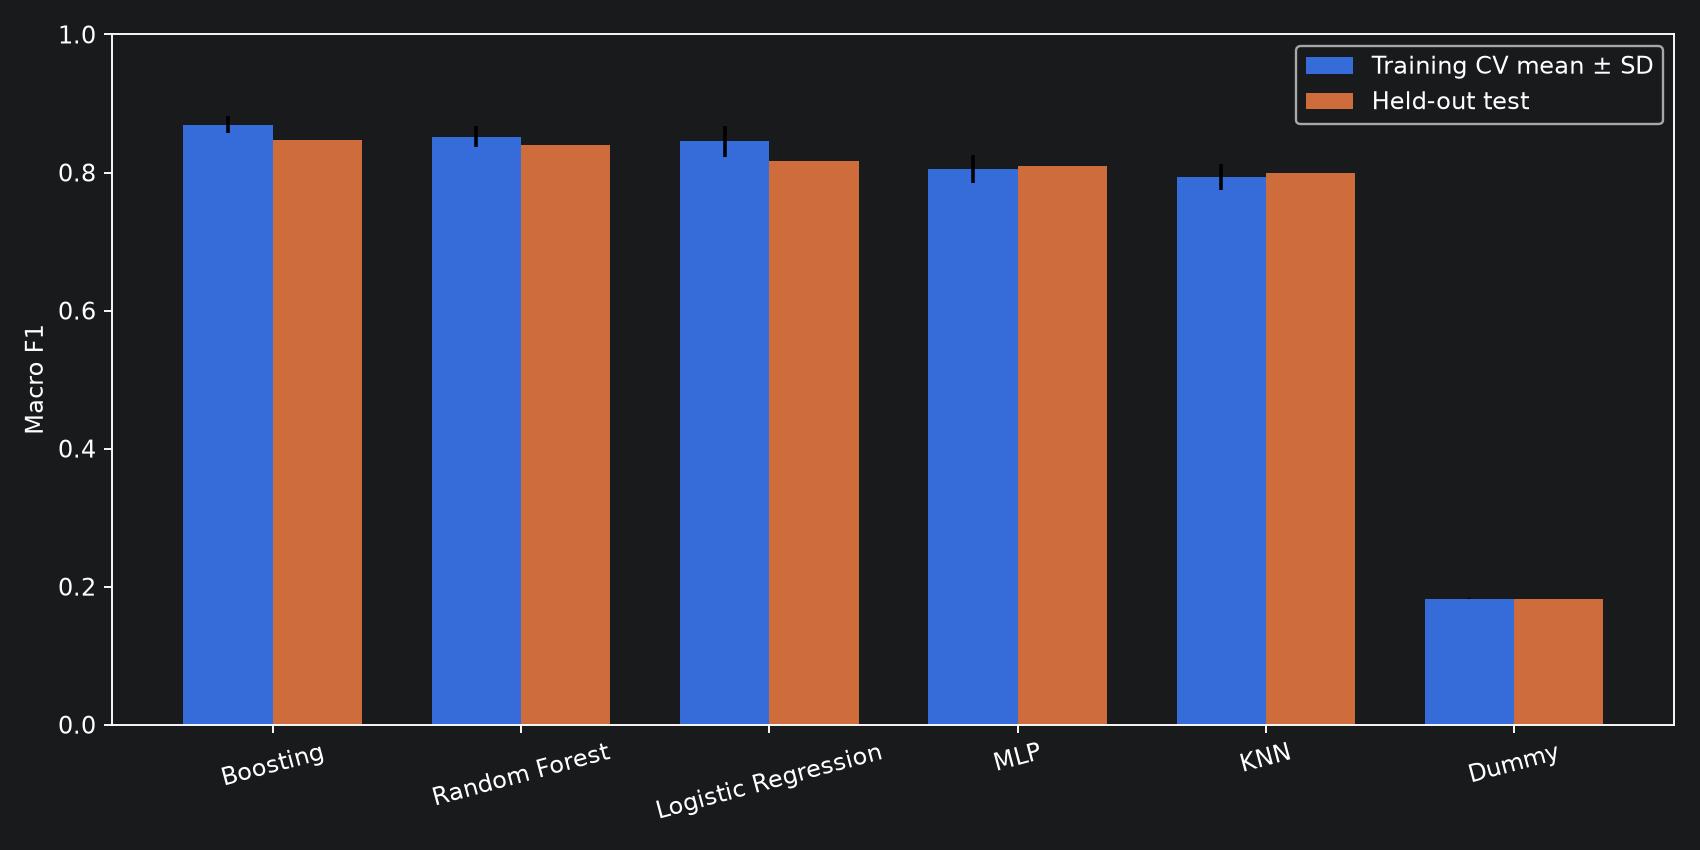

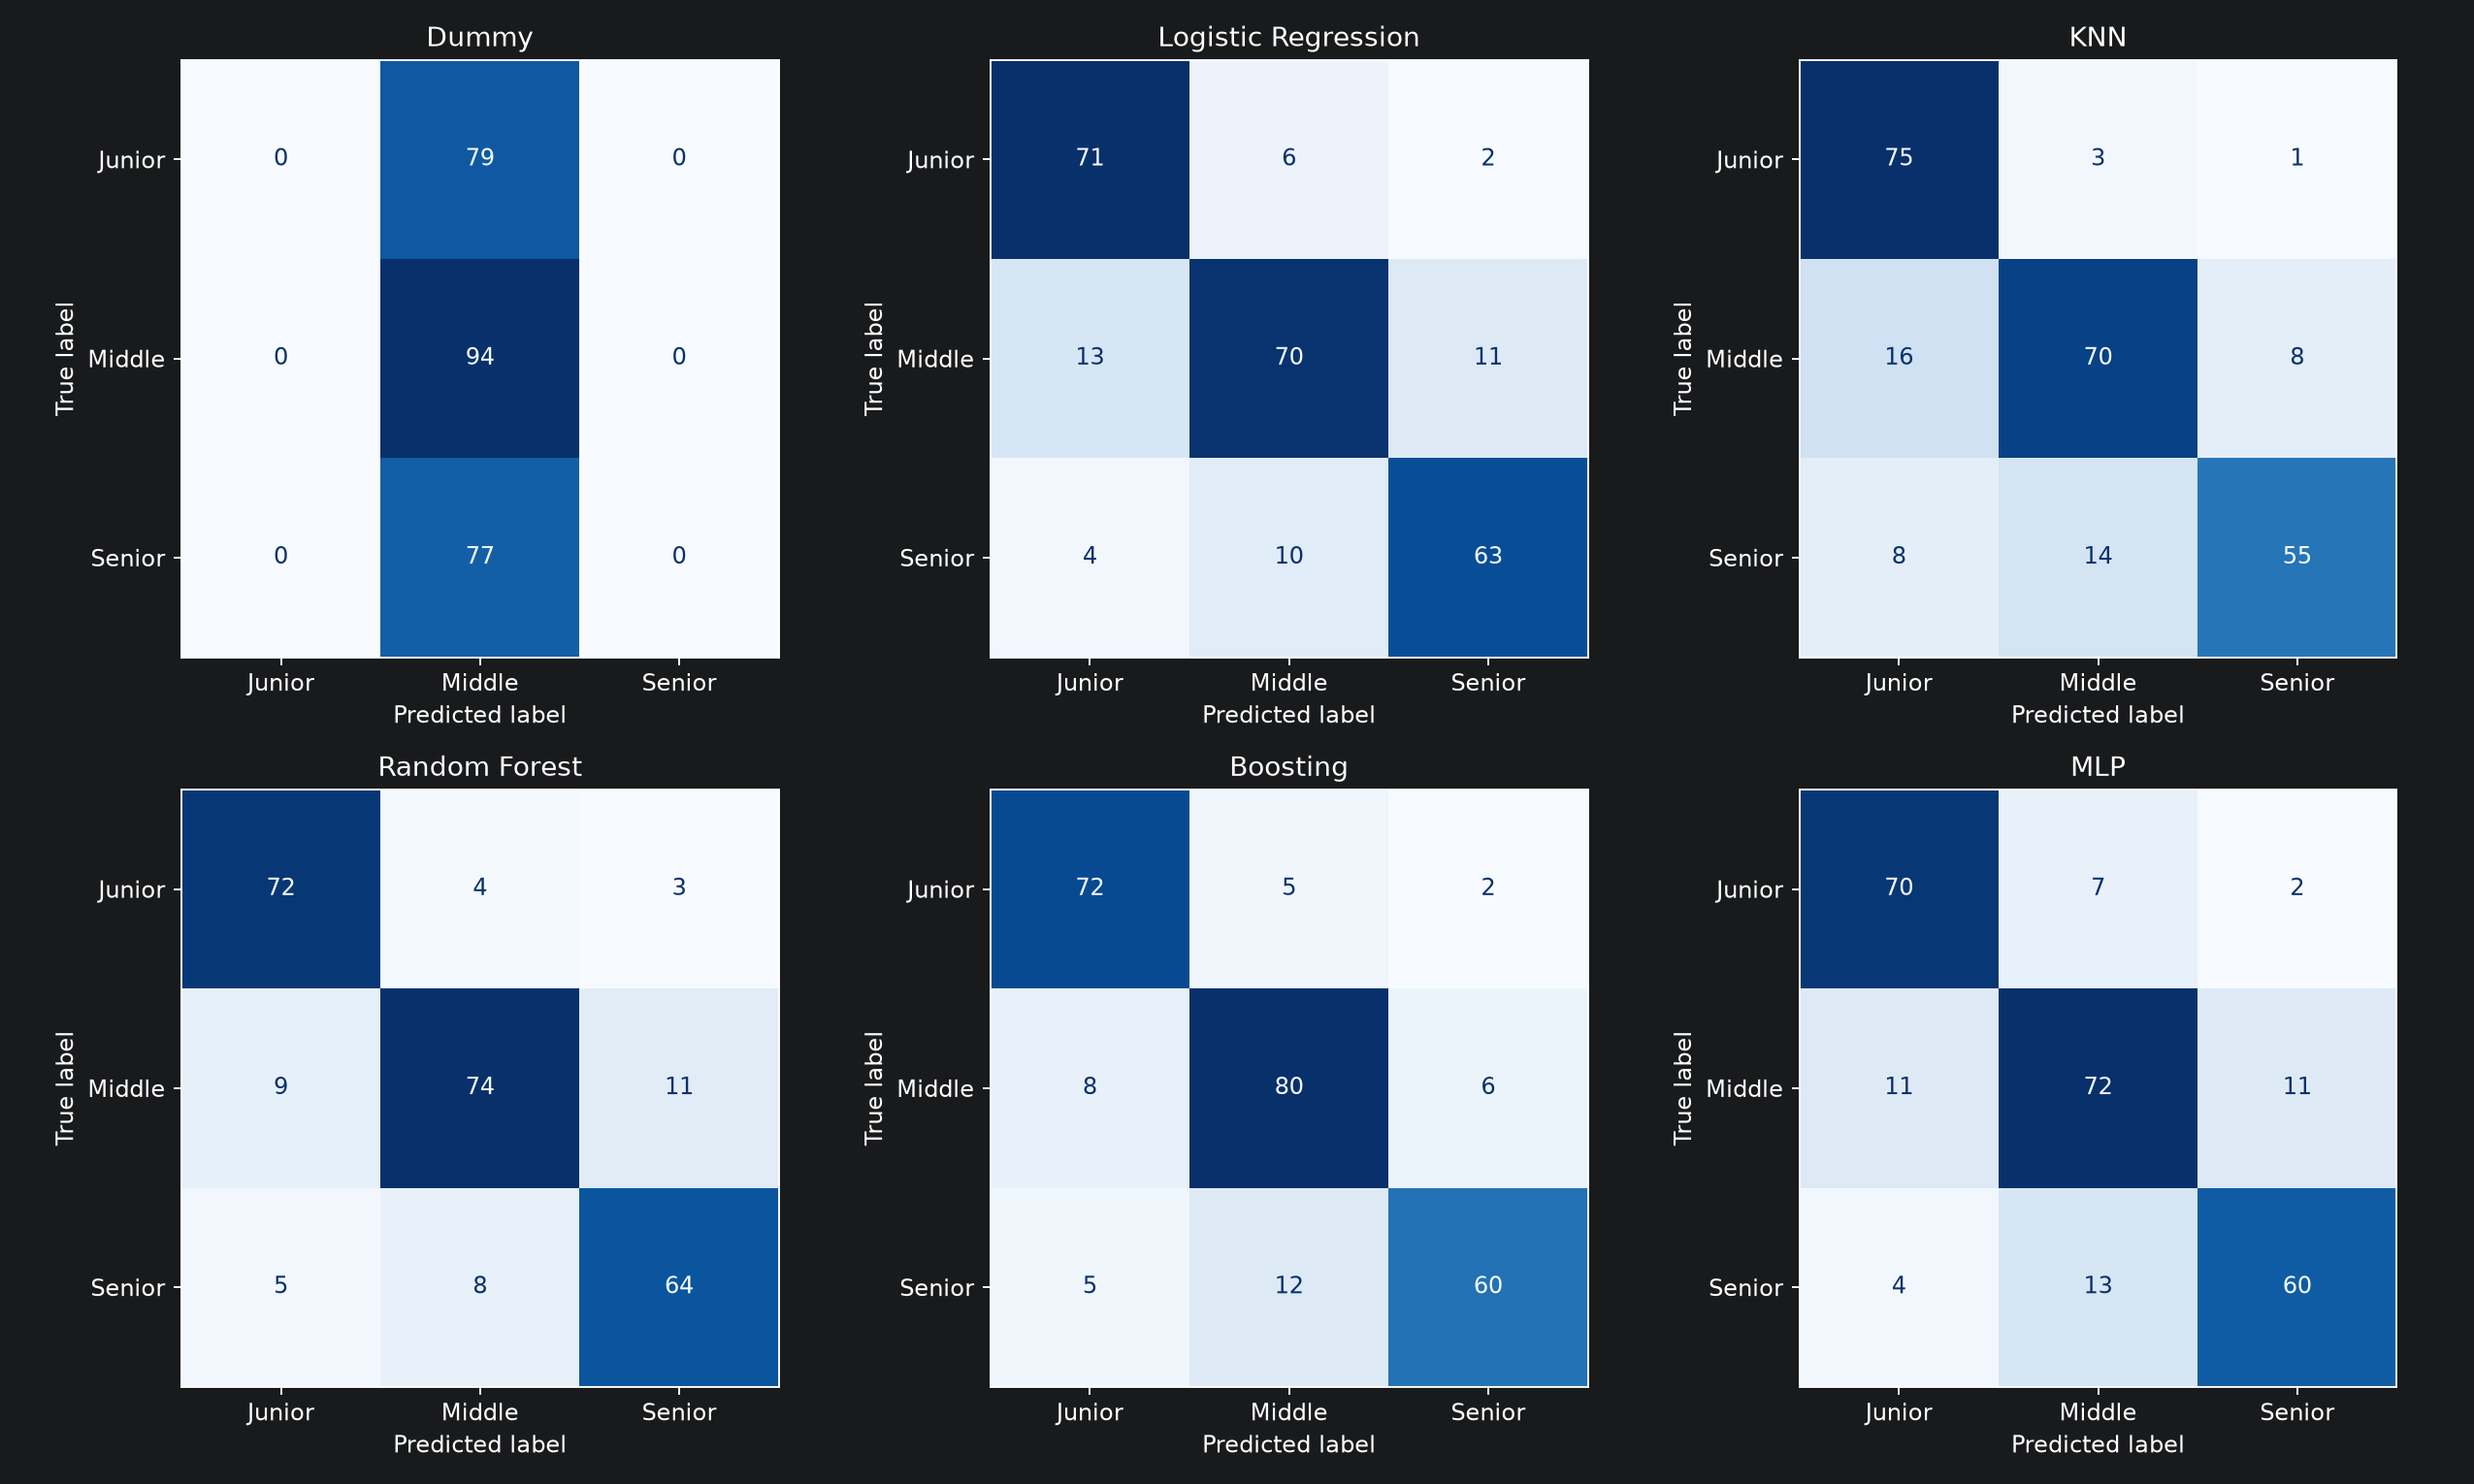

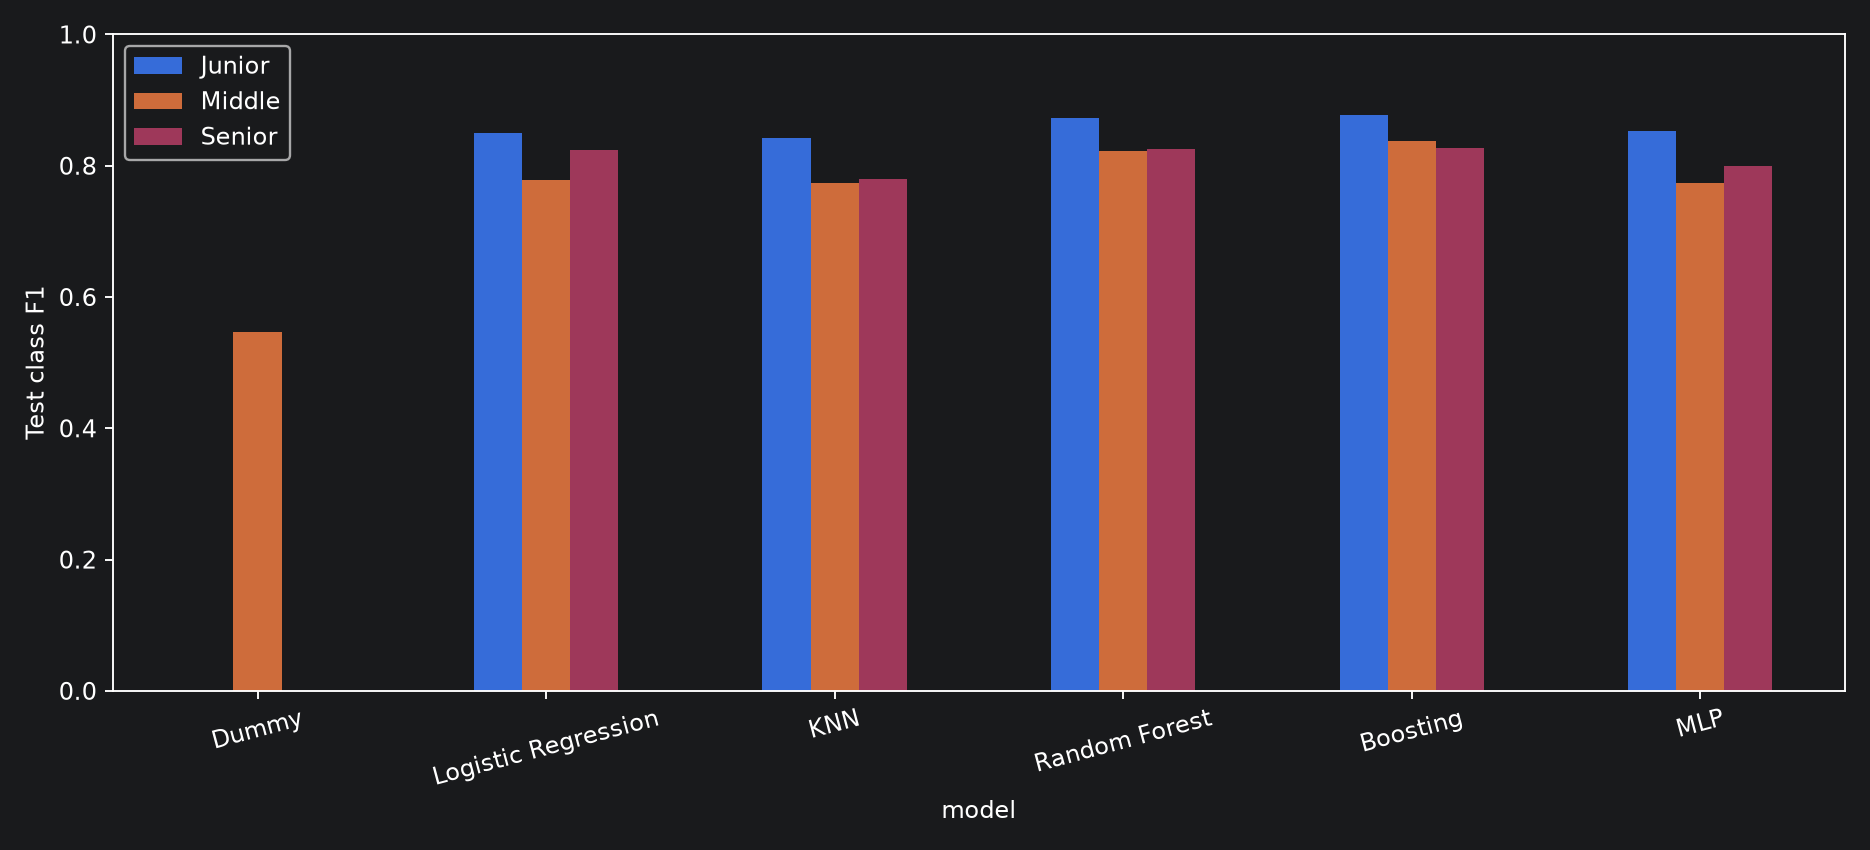

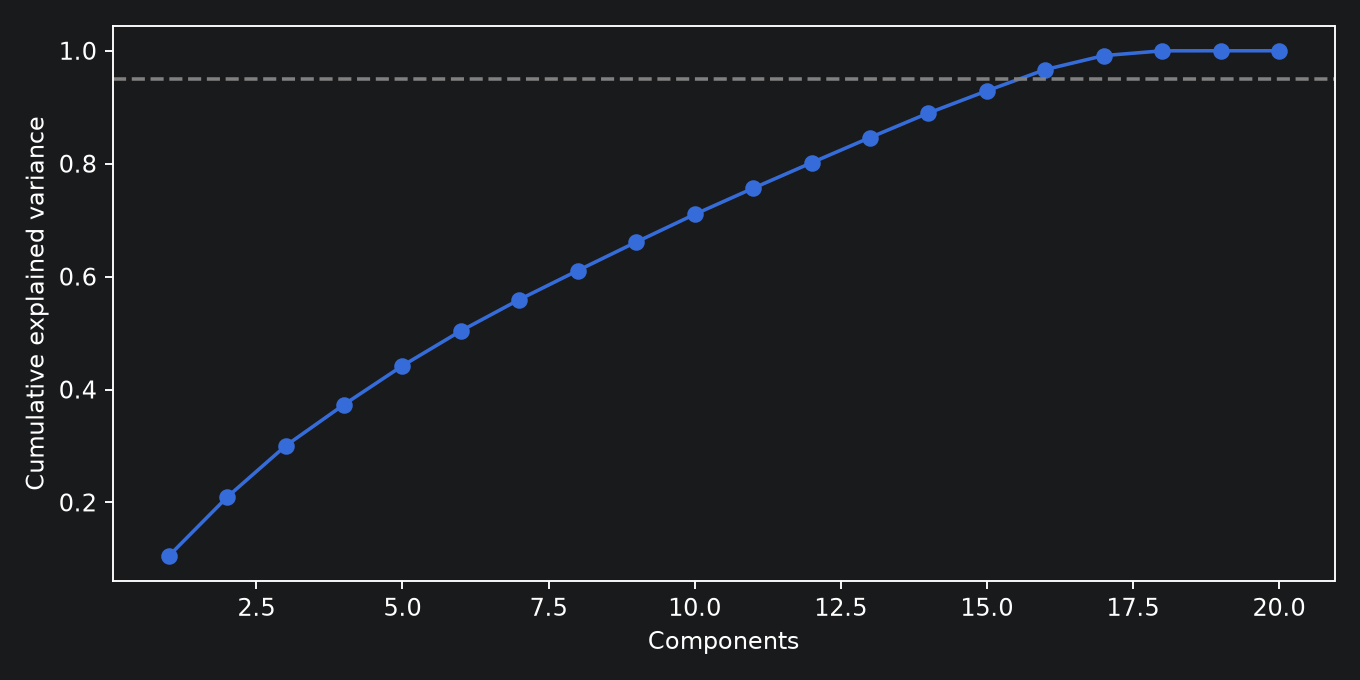

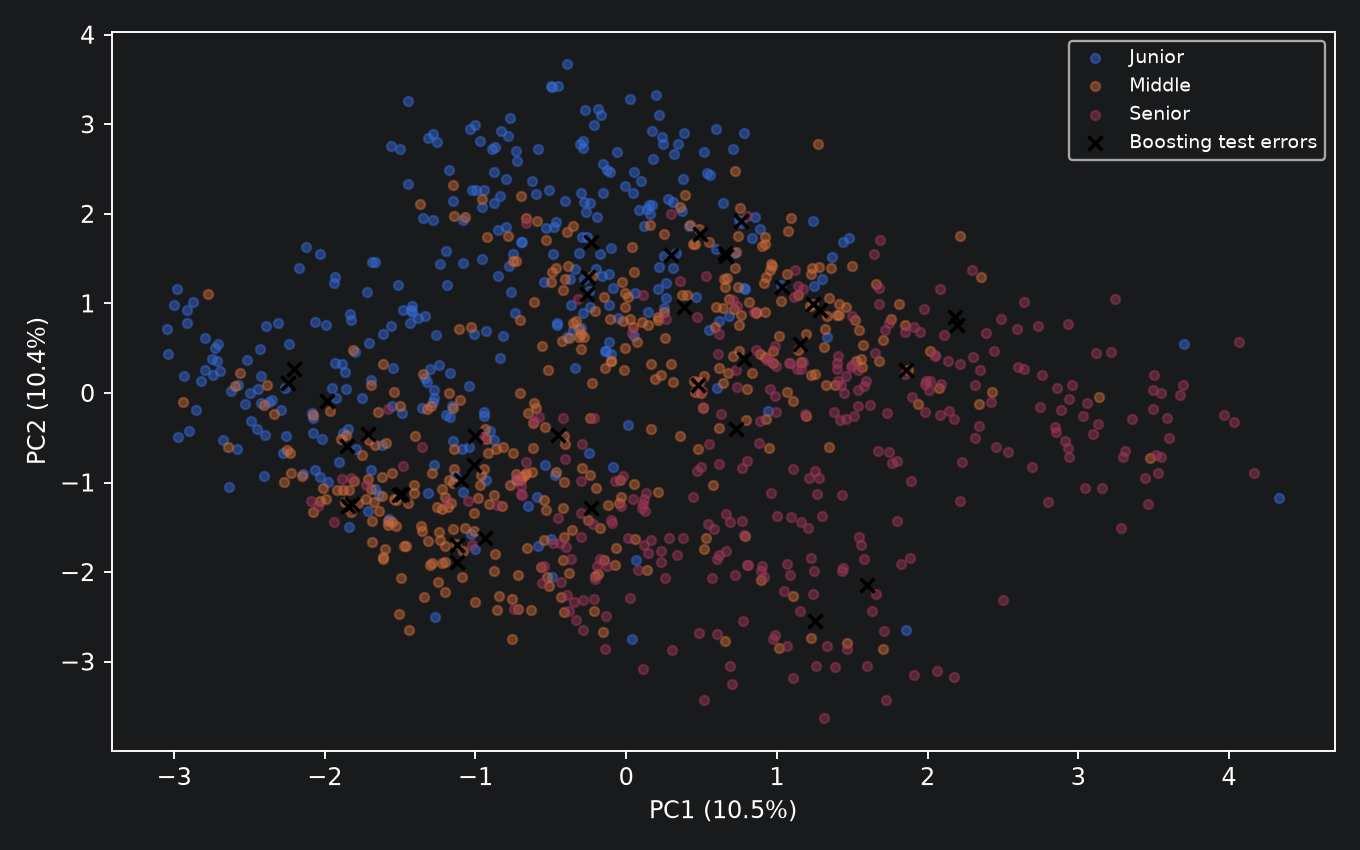

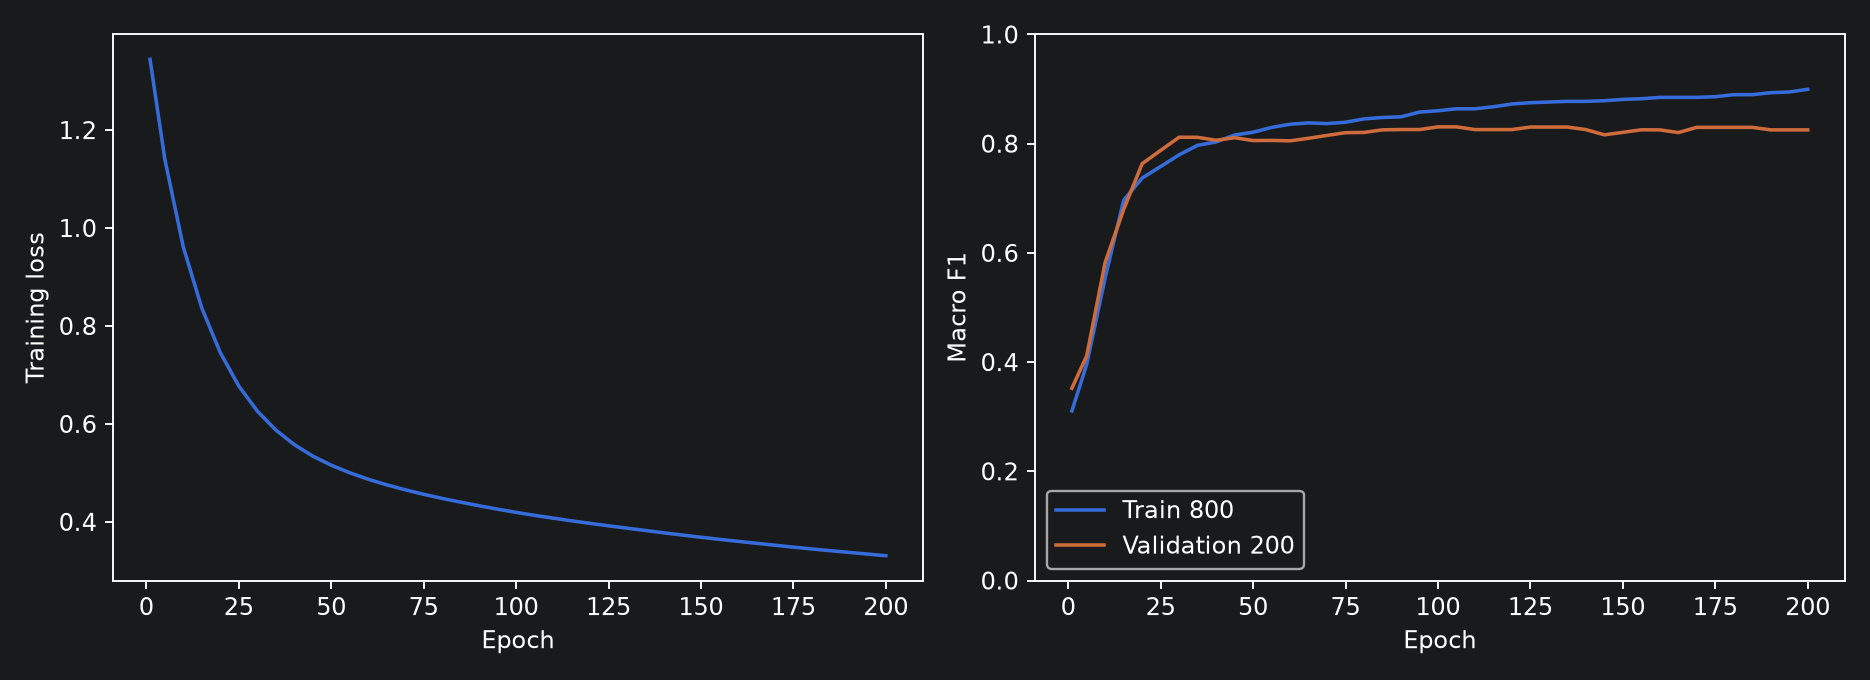

In [4]:
for name in ['historical_reproduction', 'scenario_A_corrected', 'pca_lr_cv', 'mlp_learning_progress', 'error_by_salary', 'pca_examples']:
    print(name)
    display(pd.read_csv(ROOT / 'results' / 'tables' / (name + '.csv')).head(12))
for figure in ['model_comparison', 'confusion_matrices', 'class_f1', 'pca_variance', 'pca_projection', 'mlp_learning']:
    display(Image(filename=str(ROOT / 'results' / 'figures' / (figure + '.png'))))

## Interpretation and limitations
Boosting is selected by training CV. Compare it with corrected LR, both ensembles and MLP in the table above; test ranking never controls selection. The full interpretation, actual error examples and PCA loadings are in CONCLUSIONS.md and results/tables. Some MLP fits hit their iteration cap; inspect the explicit training-only holdout curves and mlp_convergence.json. Scenario A reproduces target proxies and remains outside the fair ranking. Description length may retain indirect template/title signals. Synthetic patterns and heuristic labels prevent claims about genuine hiring markets. The Final plan uses the existing descriptions matched by synthetic ID, with explicit masking and a separately governed real-data study only if lawful and independently sourced.